In [31]:
import sys

print(sys.executable)

c:\Users\bhoom\OneDrive\Documents\Product_Classification\.venv\Scripts\python.exe


In [32]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import ucimlrepo

print("All libraries imported successfully!")

All libraries imported successfully!


# Product Classification Using Machine Learning

## 1. Introduction

### 1.1 Business Problem

An online product comparison platform receives product offers from multiple merchants. Manually categorising these offers is time-consuming and can lead to incorrect product categorisation.

This project aims to develop a machine learning model that automatically predicts product categories using product titles and available product information.

### 1.2 Machine Learning Objective

The objective is to build a supervised multi-class classification model that learns from labelled product offers and predicts the appropriate category for new product offers.

## 2. Dataset Understanding

### 2.1 Dataset Acquisition

The Product Classification and Clustering dataset is obtained from the UCI Machine Learning Repository. It contains product offers collected from multiple merchants and will be used to develop a supervised product classification model.

In [33]:
import pandas as pd

# Load the locally stored dataset
df = pd.read_csv("data/pricerunner_aggregate.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [34]:
df.shape

(35311, 7)

In [35]:
df.head()

,Product ID,Product Title,Merchant ID,Cluster ID,Cluster Label,Category ID,Category Label
0,1,apple iphone 8 plus 64gb silver,1,1,Apple iPhone 8 Plus 64GB,2612,Mobile Phones
1,2,apple iphone 8 plus 64 gb spacegrau,2,1,Apple iPhone 8 Plus 64GB,2612,Mobile Phones
2,3,apple mq8n2b/a iphone 8 plus 64gb 5.5 12mp sim...,3,1,Apple iPhone 8 Plus 64GB,2612,Mobile Phones
3,4,apple iphone 8 plus 64gb space grey,4,1,Apple iPhone 8 Plus 64GB,2612,Mobile Phones
4,5,apple iphone 8 plus gold 5.5 64gb 4g unlocked ...,5,1,Apple iPhone 8 Plus 64GB,2612,Mobile Phones


In [36]:
df.columns

Index(['Product ID', 'Product Title', ' Merchant ID', ' Cluster ID',
       ' Cluster Label', ' Category ID', ' Category Label'],
      dtype='str')

### 2.2 Dataset Structure

The dataset structure is examined to understand the available attributes, data types, and number of non-null observations in each column.

In [37]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 35311 entries, 0 to 35310
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   Product ID       35311 non-null  int64
 1   Product Title    35311 non-null  str  
 2    Merchant ID     35311 non-null  int64
 3    Cluster ID      35311 non-null  int64
 4    Cluster Label   35311 non-null  str  
 5    Category ID     35311 non-null  int64
 6    Category Label  35311 non-null  str  
dtypes: int64(4), str(3)
memory usage: 1.9 MB


### 2.3 Unique Values Analysis

Unique value analysis is performed to understand the diversity of product titles, merchants, clusters and product categories within the dataset.

In [38]:
df.nunique()

Product ID         35311
Product Title      30993
 Merchant ID         306
 Cluster ID        13233
 Cluster Label     12849
 Category ID          10
 Category Label       10
dtype: int64

In [39]:
print(df.columns.tolist())

['Product ID', 'Product Title', ' Merchant ID', ' Cluster ID', ' Cluster Label', ' Category ID', ' Category Label']


In [40]:
df.columns = df.columns.str.strip()

In [41]:
df['Category Label'].value_counts()

Category Label
Fridge Freezers     5501
Mobile Phones       4081
Washing Machines    4044
CPUs                3862
Fridges             3584
TVs                 3564
Dishwashers         3424
Digital Cameras     2697
Microwaves          2342
Freezers            2212
Name: count, dtype: int64

**Observations:**

1. The dataset contains 10 distinct product categories.
2. Fridge Freezers has the highest number of product offers (5,501).
3. Freezers has the lowest number of product offers (2,212).
4. The number of product offers varies across categories, indicating some class imbalance.
5. Category distribution will be considered during model training and evaluation.

In [42]:
df['Product Title'].duplicated().sum()

np.int64(4318)

In [43]:
df[df['Product Title'].duplicated(keep=False)][
    ['Product Title', 'Merchant ID', 'Cluster ID', 'Category Label']
].head(15)

,Product Title,Merchant ID,Cluster ID,Category Label
3,apple iphone 8 plus 64gb space grey,4,1,Mobile Phones
4,apple iphone 8 plus gold 5.5 64gb 4g unlocked ...,5,1,Mobile Phones
5,apple iphone 8 plus gold 5.5 64gb 4g unlocked ...,6,1,Mobile Phones
7,apple iphone 8 plus 64gb space grey,8,1,Mobile Phones
8,apple iphone 8 plus 64gb space grey,9,1,Mobile Phones
9,apple iphone 8 plus 64gb space grey,10,1,Mobile Phones
26,apple iphone 7 plus 32gb silver,1,2,Mobile Phones
27,apple iphone 7 plus silver 32gb 4g unlocked si...,5,2,Mobile Phones
28,apple iphone 7 plus silver 32gb 4g unlocked si...,6,2,Mobile Phones
30,apple iphone 7 plus 32gb silver,9,2,Mobile Phones


In [44]:
df['Cluster ID'].value_counts().head(10)

Cluster ID
38848    27
4419     24
38849    24
1        23
4420     23
4425     23
38850    23
2        22
3        22
4        22
Name: count, dtype: int64

In [45]:
top_cluster_id = df['Cluster ID'].value_counts().idxmax()

display(
    df.loc[
        df['Cluster ID'] == top_cluster_id,
        ['Product Title', 'Merchant ID', 'Cluster ID',
         'Cluster Label', 'Category Label']
    ]
)

,Product Title,Merchant ID,Cluster ID,Cluster Label,Category Label
11507,canon ixus 185 schwarz,247,38848,Canon IXUS 185,Digital Cameras
11508,canon ixus 185 digital camera silver,248,38848,Canon IXUS 185,Digital Cameras
11509,canon ixus 185 digital camera silver,17,38848,Canon IXUS 185,Digital Cameras
11510,canon ixus 185 camera silver 20mp 8x zoom hd,4,38848,Canon IXUS 185,Digital Cameras
11511,canon ixus 185 digital compact camera,249,38848,Canon IXUS 185,Digital Cameras
11512,canon ixus 185 schwarz,41,38848,Canon IXUS 185,Digital Cameras
11513,canon ixus 185 hs digital camera silver,88,38848,Canon IXUS 185,Digital Cameras
11514,canon ixus 185 compact camera in silver,250,38848,Canon IXUS 185,Digital Cameras
11515,canon ixus 185 compact camera red,7,38848,Canon IXUS 185,Digital Cameras
11516,canon ixus 185 red,251,38848,Canon IXUS 185,Digital Cameras


**Observations:**

1. Multiple product offers can belong to the same cluster.
2. Different merchants may describe the same product differently.
3. Cluster IDs help identify groups of related product offers.
4. Cluster labels provide representative descriptions of product groups.

In [46]:
df['Product Title'].str.strip().eq('').sum()

np.int64(0)

In [47]:
df['Product Title'].head(10)

0                      apple iphone 8 plus 64gb silver
1                  apple iphone 8 plus 64 gb spacegrau
2    apple mq8n2b/a iphone 8 plus 64gb 5.5 12mp sim...
3                  apple iphone 8 plus 64gb space grey
4    apple iphone 8 plus gold 5.5 64gb 4g unlocked ...
5    apple iphone 8 plus gold 5.5 64gb 4g unlocked ...
6                 apple iphone 8 plus 64 gb space grey
7                  apple iphone 8 plus 64gb space grey
8                  apple iphone 8 plus 64gb space grey
9                  apple iphone 8 plus 64gb space grey
Name: Product Title, dtype: str

In [48]:
df.duplicated().sum()

np.int64(0)

## 3. Text Preprocessing and Feature Extraction

### 3.1 Why Text Vectorization is Required

Machine learning algorithms generally require numerical input. Product titles are textual data, so they must be converted into numerical representations before classification.

Text vectorization is the process of converting textual information into numerical features.

### 3.2 TF-IDF (Term Frequency – Inverse Document Frequency)

TF-IDF is a text representation technique that assigns numerical weights to words based on their frequency within a document and their rarity across the collection of documents.

It reduces the relative importance of frequently occurring words and gives greater importance to more informative words.

In this project, TF-IDF will be used to convert product titles into numerical features for product category classification.

## 4. Model Development

### 4.1 Defining Features and Target

Product Title is selected as the input feature (X), while Category Label is selected as the target variable (y).

The objective is to train a supervised machine learning model that learns patterns from product titles and predicts their corresponding product categories.

In [49]:
X = df['Product Title']
y = df['Category Label']

groups = df['Cluster ID']

print("Input shape:", X.shape)
print("Target shape:", y.shape)

Input shape: (35311,)
Target shape: (35311,)


### 4.2 Training and Testing Data Split

The dataset is divided into training and testing sets. The training set is used to train the classification model, while the testing set is used to evaluate its performance on previously unseen product offers.

An 80:20 split is used. Product clusters are kept together to prevent related product offers from appearing in both sets.

In [50]:
from sklearn.model_selection import GroupShuffleSplit

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 28157
Testing records: 7154


In [51]:
train_clusters = set(groups.iloc[train_idx])
test_clusters = set(groups.iloc[test_idx])

print("Overlapping clusters:", len(train_clusters &test_clusters))

Overlapping clusters: 0


### 4.3 Text Vectorization using TF-IDF

Product titles contain textual information that cannot be directly processed by traditional machine learning algorithms. TF-IDF converts these titles into numerical feature vectors by assigning weights to words based on their frequency and importance across the dataset.

We use unigram and bigram features to capture individual words as well as two-word combinations.

In [52]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    ngram_range=(1, 2),
    max_features=50000,
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training feature shape:", X_train_tfidf.shape)
print("Testing feature shape:", X_test_tfidf.shape)
print("Vocabulary size:", len(tfidf.vocabulary_))

Training feature shape: (28157, 50000)
Testing feature shape: (7154, 50000)
Vocabulary size: 50000


In [53]:
feature_names = tfidf.get_feature_names_out()

print("First 10 feature names:")
print(feature_names[:10])

First 10 feature names:
['00' '00 ghz' '00 gt' '000' '000 actuations' '001' '001 3g' '001 6ghz'
 '001 866ghz' '001 bb']


### 4.4 Model Training using Logistic Regression

Logistic Regression is used as the baseline classification algorithm to predict product categories from the TF-IDF feature vectors.

In [54]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(
    solver='saga',
    max_iter=300,
    C=1.0,
    random_state=42
)

model.fit(X_train_tfidf, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'saga'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",300
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_rati

### 4.5 Model Prediction

The trained Logistic Regression model is used to predict product categories for unseen test data.

In [55]:
y_pred = model.predict(X_test_tfidf)

print("First 10 actual categories:")
print(y_test.head(10).tolist())

print("\nFirst 10 predicted categories:")
print(y_pred[:10])

First 10 actual categories:
['Mobile Phones', 'Mobile Phones', 'Mobile Phones', 'Mobile Phones', 'Mobile Phones', 'Mobile Phones', 'Mobile Phones', 'Mobile Phones', 'Mobile Phones', 'Mobile Phones']

First 10 predicted categories:
['Mobile Phones' 'Mobile Phones' 'Mobile Phones' 'Mobile Phones'
 'Mobile Phones' 'Mobile Phones' 'Mobile Phones' 'Mobile Phones'
 'Mobile Phones' 'Mobile Phones']


### 4.6 Model Evaluation

The model is evaluated using accuracy, precision, recall and F1-score to measure its performance on unseen test data.

In [56]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy)
print("Accuracy Percentage:", accuracy * 100, "%")

Model Accuracy: 0.9493989376572547
Accuracy Percentage: 94.93989376572547 %


In [57]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

                  precision    recall  f1-score   support

            CPUs       1.00      1.00      1.00       864
 Digital Cameras       0.98      1.00      0.99       488
     Dishwashers       0.91      0.96      0.93       672
        Freezers       0.95      0.91      0.93       488
 Fridge Freezers       0.94      0.91      0.93      1094
         Fridges       0.84      0.88      0.86       648
      Microwaves       1.00      0.94      0.97       512
   Mobile Phones       0.98      0.99      0.99       865
             TVs       0.95      0.98      0.96       704
Washing Machines       0.96      0.93      0.95       819

        accuracy                           0.95      7154
       macro avg       0.95      0.95      0.95      7154
    weighted avg       0.95      0.95      0.95      7154



### 4.7 Confusion Matrix

A confusion matrix is used to compare actual product categories with predicted product categories. It helps identify which categories are correctly classified and which categories are frequently confused by the model.

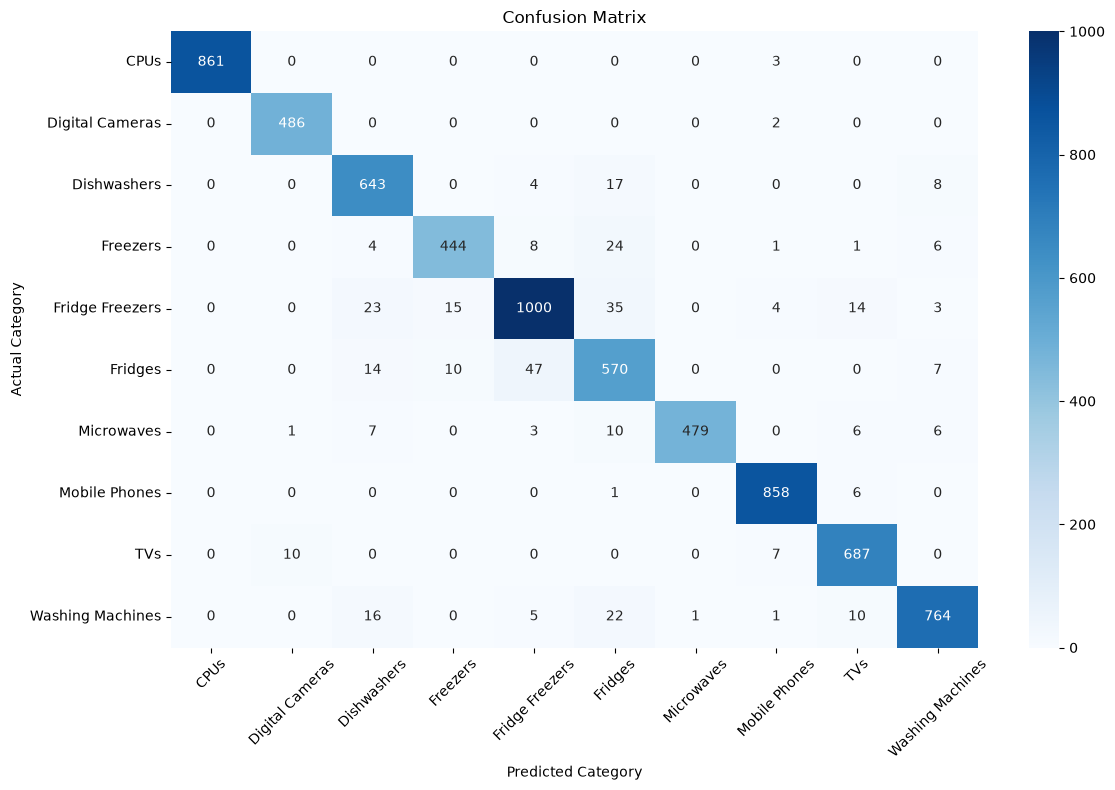

In [58]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred, labels=model.classes_)

plt.figure(figsize=(12, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=model.classes_,
    yticklabels=model.classes_
)

plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.title("Confusion Matrix")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [59]:
results = pd.DataFrame({
    'Actual': y_test,
    'Predicted': y_pred
})

misclassified = results[results['Actual'] != results['Predicted']]

print("Total misclassified:", len(misclassified))

display(misclassified.head(20))

Total misclassified: 362


,Actual,Predicted
624,Mobile Phones,TVs
2807,Mobile Phones,TVs
3358,Mobile Phones,TVs
4040,Mobile Phones,TVs
4046,Mobile Phones,TVs
4074,Mobile Phones,Fridges
4075,Mobile Phones,TVs
4278,TVs,Digital Cameras
4355,TVs,Digital Cameras
4361,TVs,Digital Cameras


In [60]:
error_analysis = pd.DataFrame({
    'Product Title': X_test,
    'Actual': y_test,
    'Predicted': y_pred
})

misclassified = error_analysis[
    error_analysis['Actual'] != error_analysis['Predicted']
]

display(misclassified.head(30))

,Product Title,Actual,Predicted
624,samsung a8 gresm a530fzvabtu,Mobile Phones,TVs
2807,samsung s5610,Mobile Phones,TVs
3358,lg k7,Mobile Phones,TVs
4040,lg u880 pink muse,Mobile Phones,TVs
4046,lg kg800 chocolate,Mobile Phones,TVs
4074,siemens sf65,Mobile Phones,Fridges
4075,samsung d500,Mobile Phones,TVs
4278,sony kd55af8bu/kd55af8bu,TVs,Digital Cameras
4355,sony kd43xf8096bu/kd43xf8096bu,TVs,Digital Cameras
4361,sony kd43xf8096baep,TVs,Digital Cameras


### Error Analysis and Observations

The classification model incorrectly predicted 362 out of 7,154 test records, resulting in a misclassification rate of approximately 5.06%.

Upon examining the misclassified product titles, the following observations were made:

1. **Insufficient textual information:** Some product titles contain only brand names and model numbers, making it difficult for the model to identify the correct product category.

2. **Similar product identifiers:** Technical model numbers and alphanumeric identifiers can appear across different product categories, resulting in incorrect predictions.

3. **Unusual product descriptions:** Some records contain incomplete, ambiguous or accessory-related descriptions that may not clearly represent their assigned category.

4. **Category confusion:** The model sometimes confuses related product categories, particularly Fridges and Fridge Freezers.

These observations indicate that product-title-based classification can be challenging when product descriptions lack meaningful category-specific keywords.